# osnosimetričen prevod toplote

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import scipy as sc
from matplotlib.colors import LogNorm
from MKR_iterative import *
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})
np.set_printoptions(linewidth=np.inf) #print in one row

## poskus mreže

In [95]:
r=1 #polmer cevi - x
L=1 #dolžina cevi - y
Nx=1 + 3 #št. točk = št. delitev +1!
Ny=1 + 3
dx=L/(Nx-1)
dy=r/(Ny-1)
print('diskretizacija x: ',dx,', y:',dy)
print('št. računskih točk:',Nx*Ny)

#diskretizacija
pointsall=np.zeros(((Nx+2)*(Ny+2)-4,2)) # brez vogalov
bulk = np.zeros(shape=(Nx*Ny,2))
#rob = np.zeros((Nx,2)) #RP1 Dirichlet
#vtok = np.zeros((Ny-1,2)) #RP2
dodatne_sp = np.zeros((Nx,2)) #dodatne za zapis DE okoli območja, Neumann RP
dodatne_zg = np.zeros((Nx,2))
dodatne_l = np.zeros((Ny,2))
dodatne_r = np.zeros((Ny,2))

#indeksi
bulk_i = np.zeros(shape=(Nx*Ny), dtype=int)
rob_i = np.zeros((Nx), dtype=int) #RP1
vtok_i = np.zeros((Ny), dtype=int) #RP2

for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        #print(i,j, index, i*dx, j*dy)
        bulk[index] = [i*dx, j*dy]
        bulk_i[index] = len(rob_i)+len(vtok_i) + index

#dodatne točke za zapis DE na robu, brez vogalov
for i in range(Nx):
    #print(i, Nx+i)
    dodatne_sp[i] = [i*dx, r+dy] #zg
    dodatne_zg[i] = [i*dx, -dy] #sp
for i in range(Ny):
    #print(2*Nx+i, 2*Nx+Ny+i)
    dodatne_l[i] = [-dx, i*dy] #levo
    dodatne_r[i] = [L+dx, i*dy] #desno

# RP
for i in range(Ny):
    #vtok[i-1] = [0, i*dy]
    vtok_i[i-1] = len(rob_i)+i-1
for i in range(Nx):
    #rob[i] = [i*dx, 0]
    rob_i[i] = i

# #pointsall[:len(vtok),:] = vtok
# #pointsall[len(vtok):len(vtok)+len(rob),:] = rob
# pointsall[:len(bulk), :] = bulk
# pointsall[-:, :] = dodatne
bulk.shape, pointsall.shape

diskretizacija x:  0.3333333333333333 , y: 0.3333333333333333
št. računskih točk: 16


((16, 2), (32, 2))

(-0.39999999999999997, 1.0666666666666667, -0.05, 1.05)

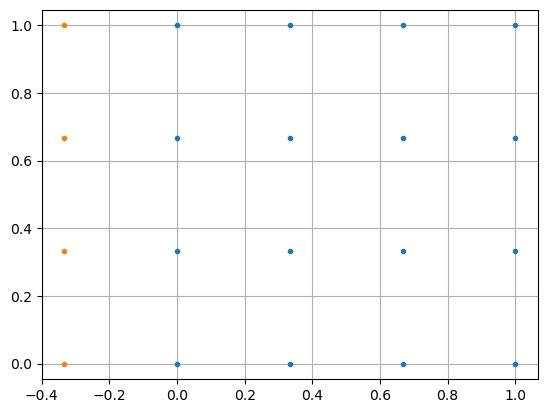

In [96]:
plt.plot(bulk[:,0],bulk[:,1],'.')
# plt.plot(rob[:,0], rob[:,1],'.')
# plt.plot(vtok[:,0], vtok[:,1],'.')
plt.plot(dodatne_l[:,0], dodatne_l[:,1],'.')
plt.grid()
plt.axis('equal')

# MKR

In [97]:
r=1 #polmer cevi - x
L=1 #dolžina cevi - y
Nx=1 + 50 #št. točk = št. delitev +1!
Ny=1 + 50
#Ny = Nx//2
dx=L/(Nx-1)
dy=r/(Ny-1)
print('št. računskih točk:',(Nx)*(Ny))

#diskretizacija
pointsall=np.zeros(((Nx)*(Ny),2))
for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        pointsall[index] = [i*dx, j*dy]
Nx,Ny,dx,dy

št. računskih točk: 2601


(51, 51, 0.02, 0.02)

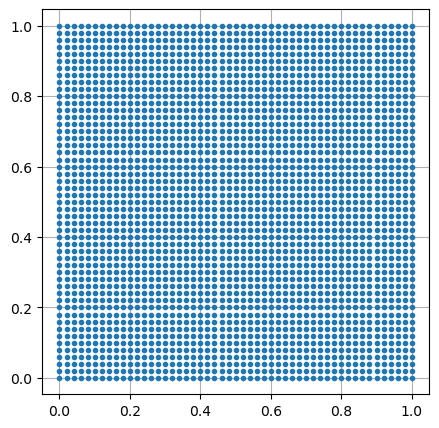

In [98]:
plt.figure(figsize=(5,5))
plt.plot(pointsall[:,0],pointsall[:,1],'.')
plt.axis('equal')
plt.grid()

In [99]:
# DE, RP
A = np.zeros(((Nx)*(Ny), (Nx)*(Ny)))
b = np.zeros(((Nx)*Ny))

# DE
for j in range(1,Ny-1):
    for i in range(1,Nx-1):
        ij_index = j*(Nx) + i #- Nx-1
        ij = 2*(1/dx**2 + 1/dy**2)
        ij_dx = -1/dx**2 - 1/(2*i*dx**2) #polarni dodatek!
        ij_dy = -1/dy**2

        #center
        A[ij_index, ij_index] += ij
        # okolica
        A[ij_index, ij_index-1] += ij_dx #levo
        A[ij_index, ij_index+1] += ij_dx #desno
        A[ij_index, ij_index-Nx] += ij_dy #dol
        A[ij_index, ij_index+Nx] += ij_dy #gor
        
        b[ij_index] = 0 #ni izvirov

# RP Dirichlet
T_rp1 = 1
T_rp2 = 0
for i in range(Nx):
    #spodaj
    #A[i, i] = 1
    #b[i] = T_rp1
    #zgoraj
    A[-Nx+i, -Nx+i] = 1
    b[-Nx+i] = T_rp1
for j in range(Ny):
    #levo
    #A[j*Nx, j*Nx] = 1
    #desno
    A[j*Nx+Nx-1, j*Nx+Nx-1] = 1
    if j*dy < r/2: #spodaj
        #b[j*Nx] = T_rp1 #L
        b[j*Nx+Nx-1] = T_rp1 #R
    else: #zgoraj
        #b[j*Nx] = T_rp2 #L
        b[j*Nx+Nx-1] = T_rp2 #R
# Neumann RP
for i in range(Nx): #spodaj
    #A[i, i] = 1/(2*dy) #centralna diferenčna shema okoli 1.vrste - vzame 0. in 2. vrsto
    #A[i, i+2*Nx] = -1/(2*dy)
    A[i, i] = 1/(dy) #diferenčna shema naprej okoli 0.vrste - vzame 0. in 1. vrsto
    A[i, i+Nx] = -1/(dy)
    b[i] = 2 #+tok noter, -ven
for j in range(1,Ny): #levo SYM RP - izolirano
    #A[j*Nx, j*Nx] = 1/(2*dx) #centralna diferenčna shema okoli 1.solpca - vzame 0. in 2. stolpec
    #A[j*Nx, j*Nx+2] = -1/(2*dx)
    A[j*Nx, j*Nx] = 1/(dx) #diferenčna shema naprej okoli 0.stolpca - vzame 0. in 1. stolpec
    A[j*Nx, j*Nx+1] = -1/(dx)
    b[j*Nx] = 0
# for j in range(0,Ny): #desno (zgoraj) toplotno izolirano, NAMESTO T_rp
#     #A[j*Nx+Nx-1, j*Nx+Nx-2] = 1/(2*dy) #centralna diferenčna shema okoli zadnjga stolpca - vzame -1. in -3. stolpec
#     #A[j*Nx+Nx-1, j*Nx+Nx-1] = -1/(2*dy)
#     A[j*Nx+Nx-1, j*Nx+Nx-2] = -1/(dy) #diferenčna shema nazaj okoli zadnjega stolpca - vzame -1. in -2. stolpec
#     A[j*Nx+Nx-1, j*Nx+Nx-1] = 1/(dy)
#     b[j*Nx+Nx-1] = 0

In [100]:
# LU razcep z delnim pivotiranjem - odpove za radialni del?!!, za ploščo je OK
insulated=False #zgornja polovica cilindra
A1,b1 = A_matrix(Nx,cylinder=False, insulated=insulated)
T_r = np.linalg.solve(A1,b1)#.reshape((Nx,Ny))

A,b = A_matrix(Nx, insulated=insulated)
T_lu_radial = np.linalg.solve(A,b)#.reshape((Nx,Ny))
# Cholesky - ni SYM!
#T_c = sc.linalg.cho_solve((A,False),b)

In [9]:
N = 628
T_j = jacobi(A,b, N=N, insulated=insulated)#.reshape((Nx,Ny))
res_jacobi = np.sum(np.abs(T_j-T_r))
res_jacobi

996.4515601861199

In [10]:
T_g = gauss_seidel(A,b, N=N, insulated=insulated)#.reshape((Nx,Ny))
res_gauss = np.sum(np.abs(T_g-T_r))
res_gauss

724.8460047498946

In [11]:
omega = 2/(1+np.pi/Nx) #ocena
# omega=0.9
print(omega)
T_sor = SOR(A,b, omega ,N=N, insulated=insulated)
res_sor = np.sum(np.abs(T_sor-T_r))
res_sor, res_gauss-res_sor

1.8839490122246525


(0.5032501978779121, 724.3427545520167)

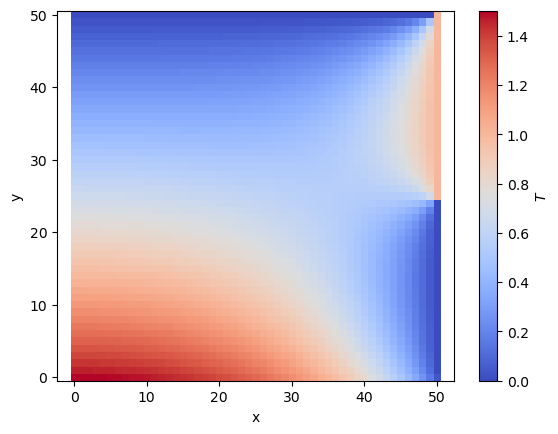

In [12]:
plt.imshow(T_sor.reshape((Nx,Ny)), cmap='coolwarm', origin='lower') #treba reshape!
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(label='$T$')

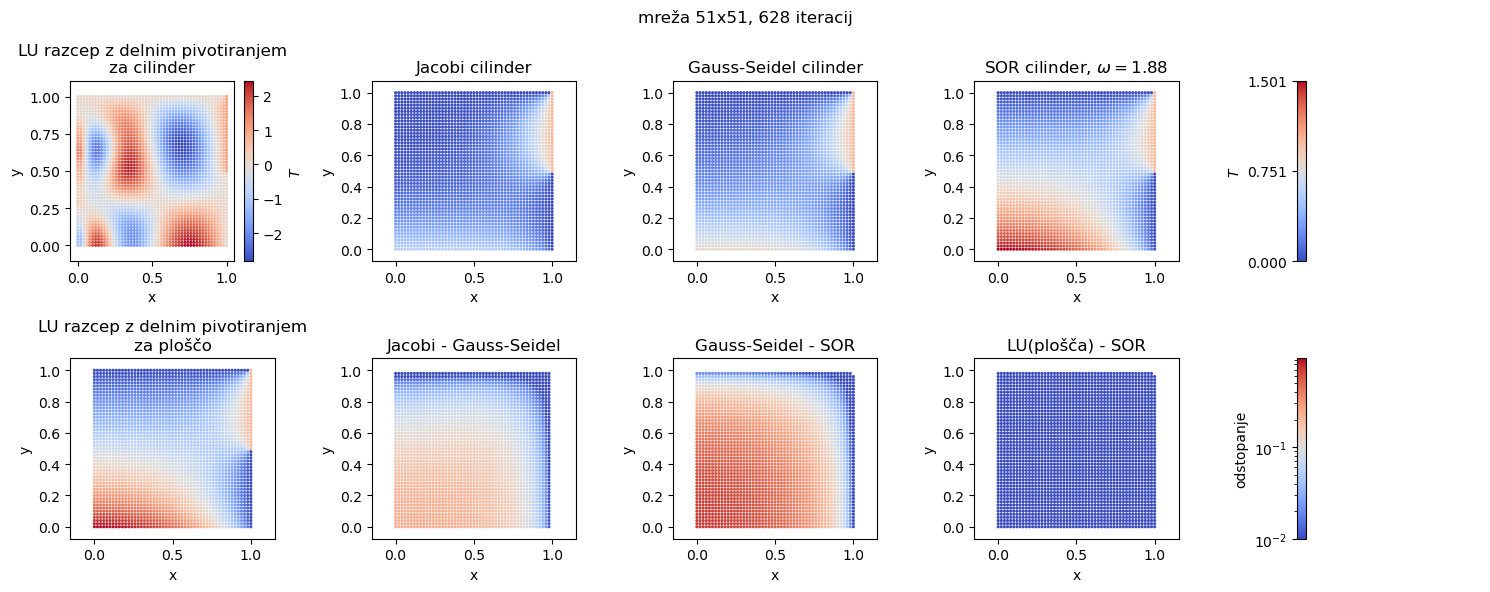

In [13]:
cmap = plt.get_cmap('coolwarm')
point_size = 5

fig, ax = plt.subplots(2, 5, figsize=(15, 6))

vmin = min(T_r.min(), T_j.min(), T_g.min(), T_sor.min())
vmax = max(T_r.max(), T_j.max(), T_g.max(), T_sor.max())

sc1 = ax[0, 0].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=T_lu_radial, cmap=cmap)
ax[0, 0].axis('equal')
ax[0, 0].set_xlabel('x')
ax[0, 0].set_ylabel('y')
ax[0, 0].set_title('LU razcep z delnim pivotiranjem\nza cilinder')
cbar = plt.colorbar(sc1, ax=ax[0, 0], label='$T$')

sc2 = ax[0, 1].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=T_j, cmap=cmap, vmin=vmin, vmax=vmax)
ax[0, 1].axis('equal')
ax[0, 1].set_xlabel('x')
ax[0, 1].set_ylabel('y')
ax[0, 1].set_title(f'Jacobi cilinder')

sc3 = ax[0, 2].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=T_g, cmap=cmap, vmin=vmin, vmax=vmax)
ax[0, 2].axis('equal')
ax[0, 2].set_xlabel('x')
ax[0, 2].set_ylabel('y')
ax[0, 2].set_title(f'Gauss-Seidel cilinder')

sc4 = ax[0, 3].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=T_sor, cmap=cmap, vmin=vmin, vmax=vmax)
ax[0, 3].axis('equal')
ax[0, 3].set_xlabel('x')
ax[0, 3].set_ylabel('y')
ax[0, 3].set_title(f'SOR cilinder, $\omega=${omega:.2f}')

ax[0, 4].cla()
ax[0, 4].axis('off')

cbar = plt.colorbar(sc4, ax=ax[0, 4], label='$T$', location='left')
cbar.set_ticks([vmin, (vmin + vmax) / 2, vmax])

sc11 = ax[1, 0].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=T_r, cmap=cmap, vmin=vmin, vmax=vmax)
ax[1, 0].axis('equal')
ax[1, 0].set_xlabel('x')
ax[1, 0].set_ylabel('y')
ax[1, 0].set_title('LU razcep z delnim pivotiranjem\nza ploščo')

vmim = min(min(np.abs(T_j - T_sor)), min(np.abs(T_g - T_sor)))
vmax = max(max(np.abs(T_j - T_sor)), max(np.abs(T_g - T_sor)))
vmin = max(vmim, 1e-2)#log scale da ni singularnosti
norm = LogNorm(vmin=vmin, vmax=vmax)

sc2 = ax[1, 1].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=(np.abs(T_j - T_g)), cmap=cmap, norm=norm)
ax[1, 1].axis('equal')
ax[1, 1].set_xlabel('x')
ax[1, 1].set_ylabel('y')
ax[1, 1].set_title('Jacobi - Gauss-Seidel')

sc3 = ax[1, 2].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=(np.abs(T_g - T_r)), cmap=cmap, norm=norm)
ax[1, 2].axis('equal')
ax[1, 2].set_xlabel('x')
ax[1, 2].set_ylabel('y')
ax[1, 2].set_title('Gauss-Seidel - SOR')

sc4 = ax[1, 3].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=(np.abs(T_sor - T_r)), cmap=cmap, norm=norm)
ax[1, 3].axis('equal')
ax[1, 3].set_xlabel('x')
ax[1, 3].set_ylabel('y')
ax[1, 3].set_title('LU(plošča) - SOR')

ax[1, 4].cla()
ax[1, 4].axis('off')

# cbar = plt.colorbar(sc2, ax=ax[1, 1], label='odstopanje Jacobi - SOR', norm=norm)
# cbar = plt.colorbar(sc3, ax=ax[1, 2], label='odstopanje GS - SOR', norm=norm)
cbar = plt.colorbar(sc4, ax=ax[1, 4], label='odstopanje', norm=norm, location='left')
#cbar.set_ticks([vmin, (vmin + vmax) / 2, vmax])

plt.suptitle(f'mreža {Nx}x{Ny}, {N} iteracij')
plt.tight_layout()
# plt.savefig(f'slike/primerjava_metod_Trp1_1_Trp2_0.pdf') #RP1: spodaj plašč, zgornja pl. RP2: plašč zgoraj

### iskanje omega z eksaktno rešitvijo

št. računskih točk: 2601


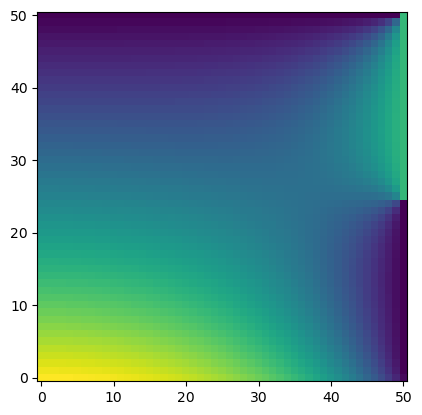

In [59]:
Nx=Ny=1 + 50 #št. točk = št. delitev +1!
dx=dy=L/(Nx-1)
print('št. računskih točk:',(Nx)*(Ny))

#diskretizacija
pointsall=np.zeros(((Nx)*(Ny),2))
for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        pointsall[index] = [i*dx, j*dy]
# DE, RP
A,b = A_matrix(Nx)
A1,b1 = A_matrix(Nx,cylinder=False)
D = np.diag(A)

T_r = np.linalg.solve(A1,b1)
plt.imshow(T_r.reshape((Nx,Ny)),origin='lower')

In [109]:
omega_list = np.append(np.linspace(0.1,1.95,20), np.linspace(1.95,2,30))
# omega_list = np.linspace(1.95,2,30)
N_max = 50000
T_ref = T_r #referenčna rešitev za ploščo?!
residual_cilj = 1

In [110]:
N_omega = []
residual_sor = []
data=[]

for i in range(len(omega_list)):
# for i in tqdm(range(len(omega_list))):
    N=1
    omega = omega_list[i]
    T_n = SOR(A,b,omega,N,insulated=insulated)
    residual = np.sum(np.abs(T_ref-T_n))
    while residual > residual_cilj and N < N_max:
        residual_old = residual
        # T_old = np.copy(T_n)
        T_n = SOR_i(D,b,omega,T_n)
        residual = np.sum(np.abs(T_ref-T_n))
        N+=1
        # print(f'{i+1}/{len(omega_list)}: omega={omega:.2f}, N={N}/{N_max}, residual={residual:.3f}',end='\r')
        if residual > residual_old: print(f'ne konvergira omega={omega}, N={N}',end='\r')
    print(f'{i+1}/{len(omega_list)}: omega={omega:.2f}, N={N}/{N_max}, residual={residual:.3f}',end='\r')
    residual_sor.append(residual)
    N_omega.append(N)
    data.append(T_n)
residual_sor = np.array(residual_sor)

In [107]:
# NI OK !!!!!!!!!!!!!!!!!!!!
# def iter(omega,A,b,T_ref,D,residual_cilj, N_max):
#     N=1
#     omega = omega_list[i]
#     T_n = SOR(A,b,omega,N)
#     residual = np.sum(np.abs(T_ref-T_n))
#     while residual > residual_cilj and N < N_max:
#         residual_old = residual
#         T_n = SOR_i(D,b,omega,T_n)
#         residual = np.sum(np.abs(T_ref-T_n))
#         N+=1
#         # print(f'{i+1}/{len(omega_list)}: omega={omega:.2f}, N={N}/{N_max}, residual={residual:.3f}',end='\r')
#         if residual > residual_old:
#             print(f'ne konvergira omega={omega}, N={N}',end='\r')
#     return N, residual

# results = []
# om=[]
# with ThreadPoolExecutor(20) as executor:
#     futures = [executor.submit(iter, omega, A, b, T_ref, D, residual_cilj, N_max) for omega in omega_list]
#     for i, future in enumerate(futures):
#         print(f'{i+1}/{len(omega_list)}', end='\r')
#         N, residual = future.result()
#         N, residual = future.result()
#         results.append((N, residual))
# N_omega, residual_sor = zip(*results)
# N_omega = np.array(N_omega)
# residual_sor = np.array(residual_sor)

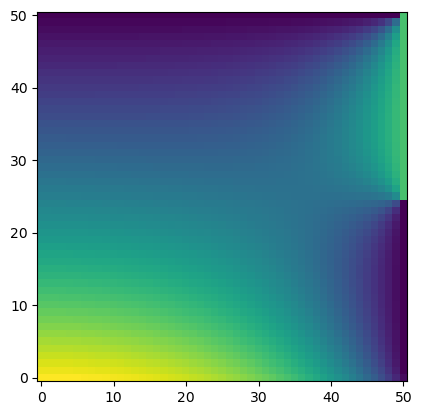

In [111]:
i=0
plt.imshow(data[i].reshape((Nx,Ny)),origin='lower')

In [83]:
N=1
T_n = jacobi(A,b,N)
residual = np.sum(np.abs(T_ref-T_n))
while residual > residual_cilj and N < N_max:
    residual_old = residual
    T_old = np.copy(T_n)
    T_n = jac_i(D,b,T_n)
    residual = np.sum(np.abs(T_r-T_n))
    N+=1
    print(f'{N}/{N_max}: residual {residual:.2f}',end='\r')
    if residual > residual_old: print('ne konvergira')
N_jac = N
res_jacobi = residual

In [84]:
N=1
T_n = jacobi(A,b,N)
residual = np.sum(np.abs(T_ref-T_n))
while residual > residual_cilj and N < N_max:
    residual_old = residual
    T_old = np.copy(T_n)
    T_n = GS_i(D,b,T_n)
    residual = np.sum(np.abs(T_r-T_n))
    N+=1
    print(f'{N}/{N_max}: residual {residual:.2f}',end='\r')
    if residual > residual_old: print('ne konvergira')
N_gs = N
res_gauss = residual

array([1.99310345, 1.99482759, 1.99655172, 1.99827586, 2.        ])

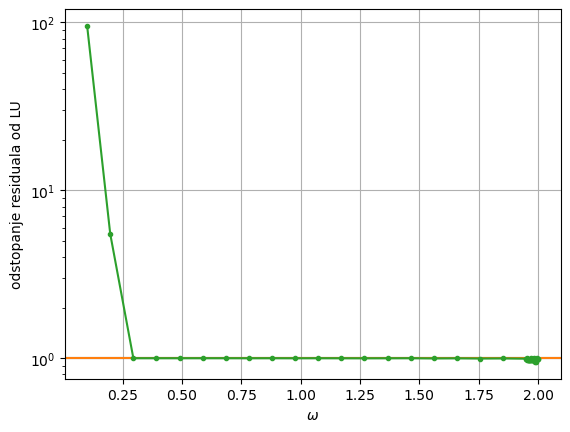

In [112]:
plt.axhline(res_jacobi, color='C0')
plt.axhline(res_gauss, color='C1')
plt.plot(omega_list, residual_sor, '.-C2')
plt.grid()
plt.yscale('log')
plt.xlabel('$\omega$')
plt.ylabel('odstopanje residuala od LU')
omega_list[-5:]

(1.9879310344827585, 156)

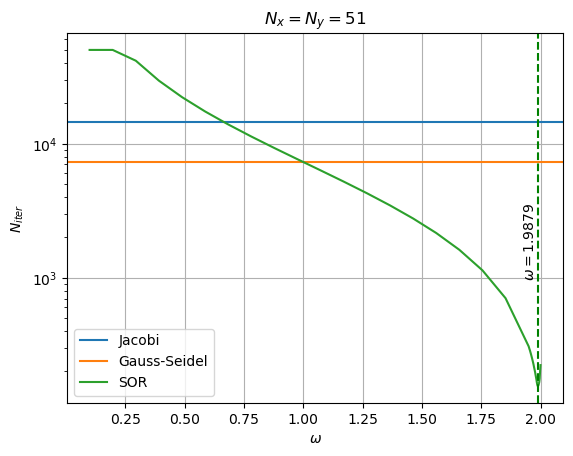

In [128]:
omega_min = omega_list[np.argmin(N_omega)]
N_min = min(N_omega)
plt.axhline(N_jac, color='C0', label='Jacobi')
plt.axhline(N_gs, color='C1', label='Gauss-Seidel')
plt.plot(omega_list, N_omega, '-C2',label='SOR')
plt.axvline(omega_min, c='g', ls='--')
plt.text(omega_min-0.06, 1000, f'$\omega={omega_min:.4f}$', rotation='vertical')
plt.grid()
plt.legend()
plt.yscale('log')
plt.xlabel('$\omega$')
plt.ylabel('$N_{iter}$')
plt.title(f'$N_x=N_y={Nx}$')
# plt.savefig('./slike/primerjava_LU.pdf')
omega_min, N_min

### omega opt

In [105]:
Nx=Ny=1 + 50 #št. točk = št. delitev +1!
dx=dy=L/(Nx-1)
print('št. računskih točk:',(Nx)*(Ny))

#diskretizacija
pointsall=np.zeros(((Nx)*(Ny),2))
for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        pointsall[index] = [i*dx, j*dy]
# DE, RP
A,b = A_matrix(Nx)
D = np.diag(A)
A1,b1 = A_matrix(Nx,cylinder=False)
T_r = np.linalg.solve(A1,b1)

št. računskih točk: 2601


1.8839490122246525


(1549.5022418104656, 0.004655366232327651, 7.806231738533957e-10)

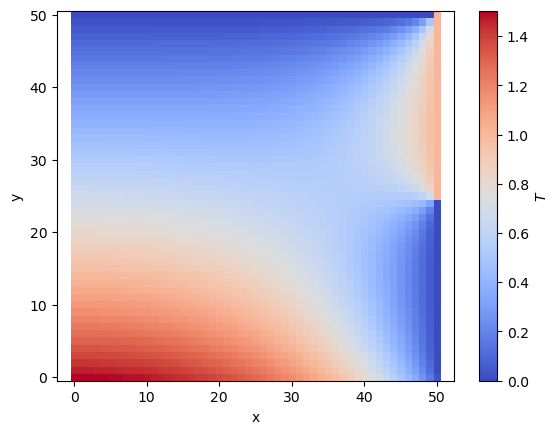

In [106]:
############################### določanje števila iteracij
# T_ref = gauss_seidel(A,b, N=1000) #referenca
# res_ref= np.sum(np.abs(T_ref))

omega = 2/(1+np.pi/Nx) #ocena
print(omega)
Nref=10000
T_ref = SOR(A,b, omega ,N=Nref)
res_ref= np.sum(np.abs(T_ref))

plt.imshow(T_ref.reshape((Nx,Ny)), cmap='coolwarm', origin='lower') #treba reshape!
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(label='$T$')
res_ref, res_ref-1549.4975864442333, np.sum(np.abs(T_ref-T_r))

In [107]:
residual_cilj = 0.3 #željeno RELATIVNO izboljšanje rezultata
N_max = 1e6
N0 = 10
D = np.diag(A)

N = N0
T_0 = jacobi(A,b,N=N0)
T_n = T_0
residual_0 = np.sum(np.abs(T_ref-T_0))
residual = residual_0
while abs((residual_0-residual)/residual_0) < residual_cilj and N < N_max:
    T_old = np.copy(T_n)
    T_n = jac_i(D,b,T_old)
    residual = np.sum(np.abs(T_ref-T_n))
    N+=1
    print(f'{N}/{N_max}: residual {(residual_0-residual)/residual_0:.2f}',end='\r')
    if residual > residual_0: print('ne konvergira')
N_jac = N
T_jac = T_n

In [108]:
N=N0
T_0=T_n = gauss_seidel(A,b,N0)
residual_0 = np.sum(np.abs(T_ref-T_0))
residual = residual_0
while abs((residual_0-residual)/residual_0) < residual_cilj and N < N_max:
    T_old = np.copy(T_n)
    T_n = GS_i(D,b,T_old)
    residual = np.sum(np.abs(T_ref-T_n))
    N+=1
    print(f'{N}/{N_max}: residual {(residual_0-residual)/residual_0:.2f}',end='\r')
    if residual > residual_0: print('ne konvergira')
T_gs = T_n
N_gs = N

In [109]:
N_omega = []
# omega_list = np.linspace(0.1, 2, 10)
omega_list = np.append(np.linspace(0.1,1.95,20), np.linspace(1.95,2,30))
for i in range(len(omega_list)):
    omega = omega_list[i]
    N=N0
    T_0=T_n = SOR(A,b,omega,N0)
    residual_0 = np.sum(np.abs(T_ref-T_0))
    residual = residual_0
    while abs((residual_0-residual)/residual_0 < residual_cilj) and N < N_max:
        #print(f'{N}/{N_max}: residual {residual:.2f}',end='\r')
        T_old = np.copy(T_n)
        T_n = SOR_i(D,b,omega,T_old)
        residual = np.sum(np.abs(T_ref-T_n))
        N+=1
        if residual > residual_0: print(f'ne konvergira: omega={omega:.3f}, N={N}',end='\r')
    if N == N_max: print(f'\n doseženo max iteracij: omega={omega:.3f}, r={(residual_0-residual)/residual_0:.3f}')
    #print(f'N {N}/{N_max}: residual {residual:.2f}\n\n',end='\r')
    print(f'{i+1}/{len(omega_list)}: omega={omega:.2f}, N={N}',end='\r')
    N_omega.append(N)

Text(0.5, 1.0, '$N_x=N_y=$51')

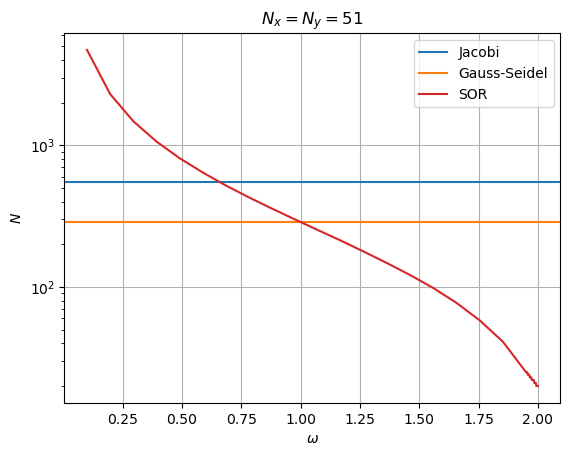

In [110]:
plt.axhline(N_jac,color='C0', label='Jacobi')
plt.axhline(N_gs,color='C1', label='Gauss-Seidel')
plt.plot(omega_list, N_omega,'-C3',label='SOR')
plt.yscale('log')
plt.xlabel('$\omega$')
plt.ylabel('$N$')
plt.legend()
plt.grid()
plt.title(f'$N_x=N_y=${Nx}')
#plt.savefig(f'slike/N_iter_Nx{Nx}.pdf')

In [4]:
################################## NOV Nx=Ny !!!!!!!!!!!!
Nx=1 + 100 #št. točk = št. delitev +1!
Ny=1 + 100
dx=L/(Nx-1)
dy=r/(Ny-1)
print('št. računskih točk:',(Nx)*(Ny))

#diskretizacija
pointsall=np.zeros(((Nx)*(Ny),2))
for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        pointsall[index] = [i*dx, j*dy]
# DE, RP
A,b = A_matrix(Nx)
D = np.diag(A)
A1,b1 = A_matrix(Nx,cylinder=False)
T_r = np.linalg.solve(A1,b1)

NameError: name 'L' is not defined

1.9396668982384437


(6022.690345837314, 2.3408288193762852e-08)

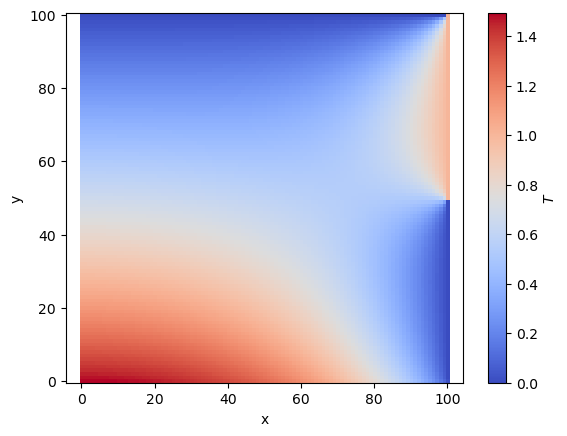

In [184]:
#nov_Nx !!! referenca mora biti OK
omega = 2/(1+np.pi/Nx) #ocena
print(omega)
Nref=5000
T_ref = SOR(A,b, omega ,N=Nref)
res_ref= np.sum(np.abs(T_ref))

plt.imshow(T_ref.reshape((Nx,Ny)), cmap='coolwarm', origin='lower') #treba reshape!
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(label='$T$')
res_ref, np.sum(np.abs(T_ref-T_r))

In [185]:
N = N0
T_0 = jacobi(A,b,N=N0)
T_n = T_0
residual_0 = np.sum(np.abs(T_ref-T_0))
residual = residual_0
while (residual_0-residual)/residual_0 < residual_cilj and N < N_max:
    T_old = np.copy(T_n)
    T_n = jac_i(D,b,T_old)
    residual = np.sum(np.abs(T_ref-T_n))
    N+=1
    print(f'{N}/{N_max}: residual {(residual_0-residual)/residual_0:.2f}',end='\r')
    if residual > residual_0: print('ne konvergira')
N_jac_2 = N
T_jac_2 = T_n

In [186]:
N=N0
T_0=T_n = gauss_seidel(A,b,N0)
residual_0 = np.sum(np.abs(T_ref-T_0))
residual = residual_0
while (residual_0-residual)/residual_0 < residual_cilj and N < N_max:
    T_old = np.copy(T_n)
    T_n = GS_i(D,b,T_old)
    residual = np.sum(np.abs(T_ref-T_n))
    N+=1
    print(f'{N}/{N_max}: residual {(residual_0-residual)/residual_0:.2f}',end='\r')
    if residual > residual_0: print('ne konvergira')
T_gs_2 = T_n
N_gs_2 = N

In [187]:
N_omega_2 = []
for i in range(len(omega_list)):
    omega = omega_list[i]
    N=N0
    T_0=T_n = SOR(A,b,omega,N0)
    residual_0 = np.sum(np.abs(T_ref-T_0))
    residual = residual_0
    while (residual_0-residual)/residual_0 < residual_cilj and N < N_max:
        #print(f'{N}/{N_max}: residual {residual:.2f}',end='\r')
        T_old = np.copy(T_n)
        T_n = SOR_i(D,b,omega,T_old)
        residual = np.sum(np.abs(T_ref-T_n))
        N+=1
        if residual > residual_0: print(f'ne konvergira: omega={omega:.3f}, N={N}',end='\r')
    if N == N_max: print(f'\n doseženo max iteracij: omega={omega:.3f}, r={(residual_0-residual)/residual_0:.3f}')
    #print(f'N {N}/{N_max}: residual {residual:.2f}\n\n',end='\r')
    print(f'{i+1}/{len(omega_list)}: omega={omega:.2f}, N={N}',end='\r')
    N_omega_2.append(N)

In [197]:
#optimalni omega - shranjeno v 5.nal_iteracije!!
omega_opt1 = omega_list[np.argmin(N_omega)]
omega_opt2 = omega_list[np.argmin(N_omega_2)]
print(omega_opt1, omega_opt2)
N_omega[45:50], np.argmin(N_omega)

1.993103448275862 2.0


([20, 20, 20, 20, 20], 45)

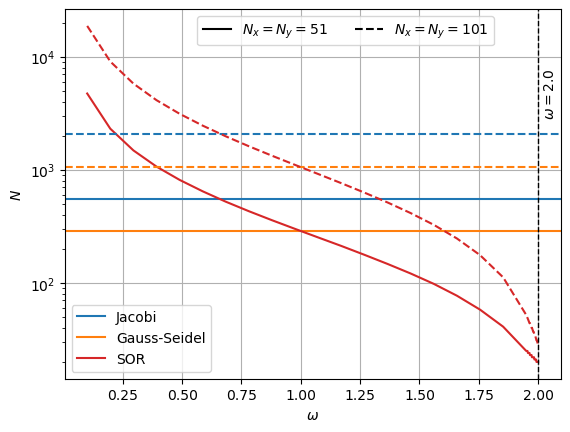

In [200]:
#Nx=Ny=51
plt.axhline(N_jac,color='C0', label='Jacobi')
plt.axhline(N_gs,color='C1', label='Gauss-Seidel')
plt.plot(omega_list, N_omega,'-C3',label='SOR')
# index = np.argmin(N_omega)
# plt.axvline(omega_list[index], color='k', linewidth=1)
# plt.text(omega_list[index]-0.05, 3e3, '$\omega=$'+str(round(omega_list[index],5)), rotation='vertical')

#Nx=Ny=101
plt.axhline(N_jac_2,linestyle='--', color='C0')
plt.axhline(N_gs_2,linestyle='--', color='C1')
plt.plot(omega_list, N_omega_2,'--C3')
index = np.argmin(N_omega_2)
plt.axvline(omega_list[index], color='k', ls='--', linewidth=1)
plt.text(omega_list[index]+0.02, 3e3, '$\omega=$'+str(round(omega_list[index],5)), rotation='vertical')

plt.yscale('log')
plt.xlabel('$\omega$')
plt.ylabel('$N$')
legend = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='$N_x=N_y=51$'),
                             plt.Line2D([], [], color='k', linestyle='--', label='$N_x=N_y=101$')],
                     loc='upper right', bbox_to_anchor=(0.88, 1),ncol=3)
plt.gca().add_artist(legend)
plt.legend()
plt.grid()
# plt.savefig(f'slike/N_iter_dva_Nx.pdf')

# MKV

In [23]:
A = np.zeros((Nx*Ny,Nx*Ny))
b = np.zeros((Nx*Ny))

#koeficienti
aW = aE = dy/dx
aN = aS = dx/dy
Sp = 0 #ni tokov preko zunanjih robov
Su = 0 #ni izvorov
aP = aW + aE + aN + aS - Sp
#notranje točke
for j in range(1,Ny-1):
    for i in range(1,Nx-1):
        ij_index = j*Nx + i
        A[ij_index,ij_index] += aP
        A[ij_index,ij_index-1] += -aW
        A[ij_index,ij_index+1] += -aE
        A[ij_index,ij_index+Nx] += -aN
        A[ij_index,ij_index-Nx] += -aS
        b[ij_index] += Su

# Dirichlet RP
T_rp1 = 0
T_rp2 = 1
#zgoraj
aW=aE=dy/dx
aS=dx/dy
aN=0
Su=dx/dy*T_rp1 #tok zaradi rp
Sp=-dy/dx #izvorni člen
aP = aW + aE + aN + aS - Sp
for i in range(1,Nx):
    A[-Nx+i, -Nx+i] += aP #rob
    A[-Nx+i, -Nx+i-Nx] += -aS
    A[-Nx+i, -Nx+i-1] += -aW
    A[-Nx+i, -Nx+i+1] += -aE
    if -Nx+i+1 == 0: A[-Nx+i, -Nx+i+1] -= -aE #izogib preskokom
    b[-Nx+i] += Su
#desno
aW=dy/dx
aE=0
aS=aN=dx/dy
Su_rp1=dx/dy*T_rp1 #tok zaradi rp
Su_rp2=dx/dy*T_rp2 #tok zaradi rp
Sp=-dy/dx #izvorni člen ?
aP = aW + aE + aN + aS - Sp
for j in range(Ny-1):
    A[j*Nx+Nx-1, j*Nx+Nx-1] += aP #rob
    A[j*Nx+Nx-1, j*Nx+Nx-1+Nx] += -aN
    if j*Nx+Nx-1-Nx >= Nx:A[j*Nx+Nx-1, j*Nx+Nx-1-Nx] += -aS #izogib preskokom
    A[j*Nx+Nx-1, j*Nx+Nx-1-1] += -aW
    if j*dy < L/2: b[j*Nx+Nx-1] += Su_rp1 #spodnja polovica
    if j*dy >= L/2: b[j*Nx+Nx-1] += Su_rp2 #zgornja polovica

# Neumann RP
Q_rp=-2 #-minus tok noter!!
#spodaj
aW=aE=dy/dx
aN=dx/dy
aS=0
Sp=0 #izvorni člen
Su=Q_rp/1 #tok na meji Q_rp/prevodnost zaradi rp, k=1
aP = aW + aE + aN + aS - Sp
for i in range(1,Nx-1):
    A[i, i] += aP
    A[i, i+Nx] += aN
    A[i, i+1] += -aE
    if i>=1: A[i, i-1] += -aW #izogib preskokom
    b[i] += -Su
#levo SYM
aE=dy/dx
aW=0
aN=aS=dx/dy
Sp=0 #izvorni člen
Su=0 #tok na meji = 0, saj je SYM
aP = aW + aE + aN + aS - Sp
for j in range(0,Ny):
    A[j*Nx, j*Nx] += aP
    if j*Nx+Nx<Ny*Nx: A[j*Nx, j*Nx+Nx] += -aN #izogib preskokom
    A[j*Nx, j*Nx-Nx] += -aS
    A[j*Nx, j*Nx+1] += -aE
    b[i] += Su

In [24]:
def TDMAsolver(a, b, c, d):
        '''
        TDMA solver, a b c d can be NumPy array type or Python list type.
        refer to http://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm
        and to http://www.cfd-online.com/Wiki/Tridiagonal_matrix_algorithm_-_TDMA_(Thomas_algorithm)
        '''
        nf = len(d) # number of equations
        ac, bc, cc, dc = map(np.array, (a, b, c, d)) # copy arrays
        for it in range(1, nf):
            mc = ac[it-1]/bc[it-1]
            bc[it] = bc[it] - mc*cc[it-1] 
            dc[it] = dc[it] - mc*dc[it-1]
        xc = bc
        xc[-1] = dc[-1]/bc[-1]
        for il in range(nf-2, -1, -1):
            xc[il] = (dc[il]-cc[il]*xc[il+1])/bc[il]
        return xc

In [45]:
# LU razcep z delnim pivotiranjem
T_r_mkv = np.linalg.solve(A,b)#.reshape((Nx,Ny))
np.sum(np.abs(T_r-T_r_mkv))

297.4420966116253

In [48]:
# Cholesky SYM matrika! NI OK
T_c = sc.linalg.cho_solve((A,False),b)
res_cho = np.sum(np.abs(T_c-T_r))
res_cho

1528.9336763502442

In [49]:
# metode odpovejo !?
N = 500
# T_j_mkv = jacobi(A,b, N=N)#.reshape((Nx,Ny))
# res_jacobi = np.sum(np.abs(T_j_mkv-T_r_mkv))
T_g_mkv = gauss_seidel(A,b, N=N)#.reshape((Nx,Ny))
res_gauss = np.sum(np.abs(T_g_mkv-T_r_mkv))
# omega = 2/(1+np.pi/Nx) #ocena
# T_sor_mkv = SOR(A,b, omega ,N=N)
# res_sor = np.sum(np.abs(T_sor_mkv-T_r_mkv))
# res_sor, res_gauss-res_sor

/mnt/Shared/FS/Modelska_analiza_II/MKR_iterative.py:226: RuntimeWarning: overflow encountered in scalar multiply
  u_n[ij_index] = 1/D[ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u_n[ij_index-1])
/mnt/Shared/FS/Modelska_analiza_II/MKR_iterative.py:227: RuntimeWarning: overflow encountered in scalar multiply
  + 1/dy**2*(u[ij_index+Nx] + u_n[ij_index-Nx]))
/mnt/Shared/FS/Modelska_analiza_II/MKR_iterative.py:226: RuntimeWarning: overflow encountered in scalar add
  u_n[ij_index] = 1/D[ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u_n[ij_index-1])


In [50]:
# Thomas za tridiagonalne NI OK -> 5 diag!
# d,l,u = sc.linalg.lu(A)
# T_t = TDMAsolver(l,d,u,b)

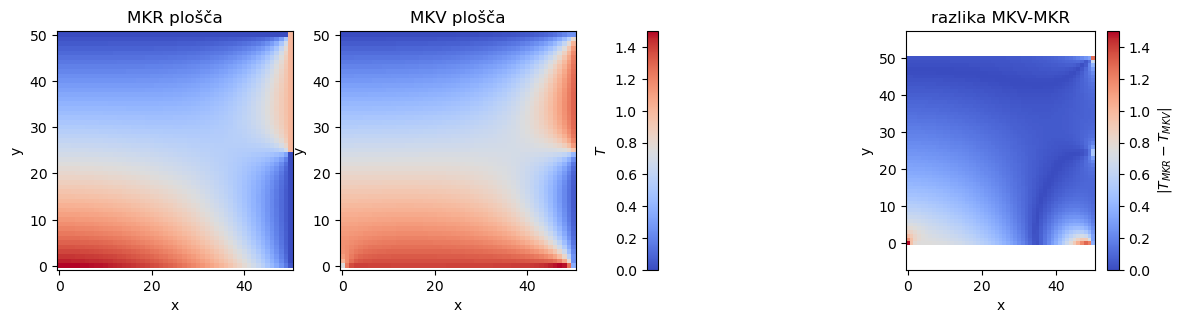

In [104]:
fig, (ax1,ax2,ax3,ax4) = plt.subplots(1,4, figsize=(14,3.1))
im = ax1.imshow(T_r.reshape((Nx,Ny)), cmap='coolwarm', origin='lower') #treba reshape! MKR
ax1.axis('equal')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('MKR plošča')

ax2.imshow(T_r_mkv.reshape((Nx,Ny)), cmap='coolwarm', origin='lower') #treba reshape! MKV
ax2.axis('equal')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_title('MKV plošča')

ax3.axis('off')
plt.colorbar(im, ax=ax3, label='$T$', location='left')

ax4.imshow(np.abs(T_r_mkv-T_r).reshape((Nx,Ny)), cmap='coolwarm', origin='lower') #treba reshape! MKV
ax4.axis('equal')
ax4.set_xlabel('x')
ax4.set_ylabel('y')
ax4.set_title('razlika MKV-MKR')
plt.colorbar(im, ax=ax4, label='$|T_{MKR}-T_{MKV}|$', location='right')
# plt.savefig('./slike/MKV.pdf')

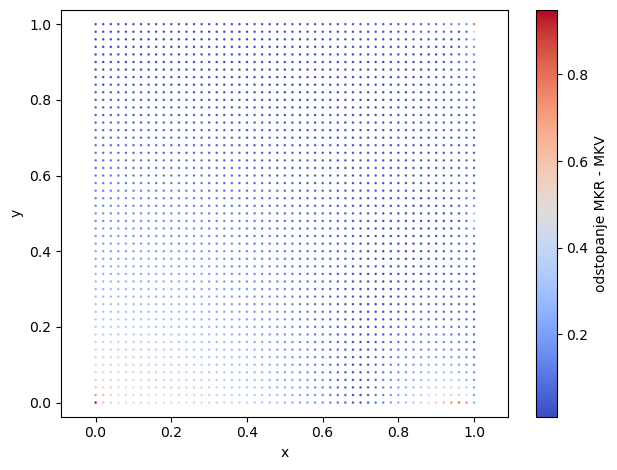

In [39]:
T_1 = T_r
T_2 = T_r_mkv
point_size = 3
cmap = plt.get_cmap('coolwarm')

vmim = min(min(np.abs(T_1 - T_2)), min(np.abs(T_1 - T_2)))
vmax = max(max(np.abs(T_1 - T_2)), max(np.abs(T_1 - T_2)))
vmin = max(vmim, 1e-2)#log scale
norm = LogNorm(vmin=vmin, vmax=vmax)

t=plt.scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=np.abs(T_1-T_2), cmap=cmap, vmin=vmin, vmax=vmax)
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(t, label='odstopanje MKR - MKV', norm=norm)
plt.tight_layout()